# Figure S9A: Translation spot counts after puromycin treatment

Per-cell tracking CSVs are in `inputs/results/`. `FigS9A.tiff` contains panel A only; the assembled `FigS9.tiff` is edited separately.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from PIL import Image

cwd = Path.cwd().resolve()
src_dir = next((p / 'src' for p in (cwd, *cwd.parents)
                if (p / 'src' / 'utilities' / 'inhibitors.py').is_file()), None)
if src_dir is None:
    raise FileNotFoundError('Start the notebook from within the UTag repository.')
notebook_dir = src_dir.parent / 'notebooks' / 'Figure_S9A_puromycin'
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))
from utilities import inhibitors as INH

INH.configure_plot_style()

Matplotlib is building the font cache; this may take a moment.


## Data Configuration
___

In [2]:
data_dir = notebook_dir / 'inputs' / 'results'

## Analysis and plot settings
___

In [3]:
inhibitor_frame_index = 4  # 0-indexed: frame when treatment was applied
frame_interval_sec = 20
use_sem = True
show_summary = False
show_individual_trajectories = False
max_percentage_threshold_after_treatment = None
treatment_label = 'Puromycin'

figsize = (4.5, 4.5)
font_family = 'Arial'
axis_label_size = 20
tick_label_size = 18
legend_font_size = 16
marker_size = 8
data_line_width = 2.5
error_bar_line_width = 2.0
error_bar_cap_thickness = 1.5
fit_line_width = 2.5
capsize = 5
ylims = (-0.02, 1.1)
xlims = (-1.5, 10)
show_runoff_time = False
show_treatment_line = False
figure_stem = 'Figure_S9A_puromycin_spot_runoff'
figures_folder = notebook_dir / 'figures'
raw_data_folder = notebook_dir / 'raw_data'
figures_folder.mkdir(parents=True, exist_ok=True)
raw_data_folder.mkdir(parents=True, exist_ok=True)


## Reporter plasmids
___

In [4]:
substring_1 = 'pNZ335'
substring_2 = 'pNZ377'


## Normalized spot counts
___

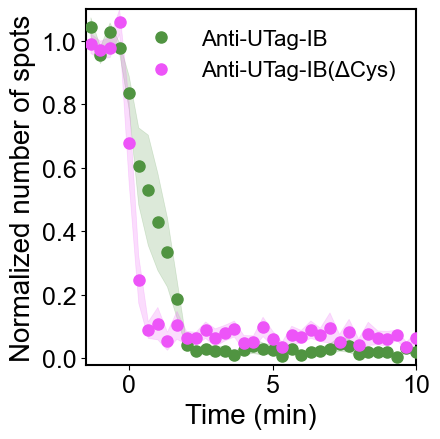

In [5]:
process_kwargs = dict(
    data_dir=data_dir,
    inhibitor_frame_index=inhibitor_frame_index,
    use_sem=use_sem,
    show_summary=show_summary,
    max_percentage_threshold_after_treatment=max_percentage_threshold_after_treatment,
    frame_interval_sec=frame_interval_sec,
    normalization_method=None,
)

_, frames_1, _, spots_per_frame_1, _, _, _, _ = INH.process_inhibitor_data(
    substring_in_data_dir=substring_1, **process_kwargs,
)
_, frames_2, _, spots_per_frame_2, _, _, _, _ = INH.process_inhibitor_data(
    substring_in_data_dir=substring_2, **process_kwargs,
)

puromycin_plot_records = []
INH.plot_multiple_inhibitors(
    full_frames_list=[frames_1, frames_2],
    intensities_normalized_list=[spots_per_frame_1, spots_per_frame_2],
    inhibitor_frame_index=inhibitor_frame_index,
    legend_labels=['Anti-UTag-IB', 'Anti-UTag-IB(ΔCys)'],
    legend_position='upper right',
    colors=['#509441', '#ED54F8'],
    figsize=figsize,
    font_family=font_family,
    axis_label_size=axis_label_size,
    tick_label_size=tick_label_size,
    legend_font_size=legend_font_size,
    marker_size=marker_size,
    data_line_width=data_line_width,
    error_bar_line_width=error_bar_line_width,
    error_bar_cap_thickness=error_bar_cap_thickness,
    fit_line_width=fit_line_width,
    capsize=capsize,
    plot_name=figure_stem,
    filename_prefix='',
    use_sem=use_sem,
    show_individual_trajectories=show_individual_trajectories,
    show_runoff_time=show_runoff_time,
    ylims=ylims,
    xlims=xlims,
    show_treatment_line=show_treatment_line,
    y_label='Normalized number of spots',
    treatment_label=treatment_label,
    source_data_collector=puromycin_plot_records,
    results_folder=figures_folder,
)

canonical_puromycin_labels = ['UTag', 'UTag_DeltaCys']
puromycin_source_rows = []
for condition, record in zip(canonical_puromycin_labels, puromycin_plot_records):
    visible_mask = (record['time'] >= xlims[0]) & (record['time'] <= xlims[1])
    for time_min, mean_value, sem_value in zip(
            record['time'][visible_mask],
            record['mean'][visible_mask],
            record['error'][visible_mask]):
        puromycin_source_rows.append({
            'condition': condition,
            'time_min': time_min,
            'mean_normalized_spot_count': mean_value,
            'sem_normalized_spot_count': sem_value,
            'n_cells': record['n_cells_total'],
        })

puromycin_source_data_df = pd.DataFrame(puromycin_source_rows)
expected_puromycin_counts = {'UTag': 35, 'UTag_DeltaCys': 35}
observed_puromycin_counts = puromycin_source_data_df['condition'].value_counts().to_dict()
if observed_puromycin_counts != expected_puromycin_counts:
    raise ValueError(
        f'Unexpected Figure S9A source-data counts: {observed_puromycin_counts}'
    )
if puromycin_source_data_df.groupby('condition')['n_cells'].first().to_dict() != {
        'UTag': 8, 'UTag_DeltaCys': 7}:
    raise ValueError('Unexpected Figure S9A cell counts.')
puromycin_source_data_df.to_csv(
    raw_data_folder / f'{figure_stem}_curves.csv',
    index=False,
)

In [6]:
with Image.open(figures_folder / f'{figure_stem}.png') as panel:
    panel.convert('RGB').save(figures_folder / 'FigS9A.tiff', compression='tiff_lzw', dpi=(600, 600))

print(f'Anti-UTag-IB: {len(spots_per_frame_1)} cells; Anti-UTag-IB(ΔCys): {len(spots_per_frame_2)} cells.')

Anti-UTag-IB: 8 cells; Anti-UTag-IB(ΔCys): 7 cells.
